# Mashariki Weather Example
This brief notebook demonstrates the use of MasharikiWeather for wind prediction. We obtain ERA5 wind speed data for Kenya and perform time series forecasting. This example is motivated by a similar example using [PeakWeather](https://github.com/MeteoSwiss/PeakWeather).

This example makes use of the [Torch Spatiotemporal (tsl)](https://torch-spatiotemporal.readthedocs.io/en/latest/) library for spatiotemporal data processing.

In [1]:
import tsl
import torch
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt

from masharikiweather.dataset import MasharikiWeatherDataset
from tsl.data import SpatioTemporalDataset

from tsl.data.datamodule import (SpatioTemporalDataModule,
                                 TemporalSplitter)
from tsl.data.preprocessing import StandardScaler
from tsl.nn.models.temporal import RNNModel

from tsl.metrics.torch import MaskedMAE, MaskedMAPE
from tsl.engines import Predictor
from tsl.utils.casting import torch_to_numpy
from tsl.metrics import numpy as numpy_metrics
from tsl.metrics import torch as torch_metrics

import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint
from pytorch_lightning.loggers import TensorBoardLogger
from lightning.pytorch.callbacks import Callback

## Initialize the pipeline

Access tokens are needed to obtain the data.

In [2]:
with open('mashariki_tokens.json', 'r') as f:
    key_data = json.load(f)

In [3]:
ds = MasharikiWeatherDataset(
    repo_id="DeKUT-DSAIL/weather-data",
    token=key_data['huggingface dataset token'], 
    source_obs=["tahmo", "ghcnd"], # Fusing hourly and daily networks
    freq="h", 
    years=[2020, 2021, 2022, 2023, 2024]
)

## Get ERA5 data
We obtain the $u$ and $v$ components of wind velocity at 10m and extract a region in central Kenya.

In [4]:
era5_data = ds.load_gridded_datasets(groups=["era5"],
                                     years=[2020])

In [5]:
era5 = era5_data['era5']
wind_u = era5[['10m_u_component_of_wind']]
wind_v = era5[['10m_v_component_of_wind']]

In [6]:
# limit to central Kenya
wind_u = wind_u.sel(lat=slice(0.4, -1.2), lon=slice(36, 38))
wind_v = wind_v.sel(lat=slice(0.4, -1.2), lon=slice(36, 38))

In [7]:
%%time
wind_u = wind_u.compute()
wind_v = wind_v.compute()

CPU times: user 40.7 s, sys: 9.64 s, total: 50.3 s
Wall time: 11min 52s


### Visualisations

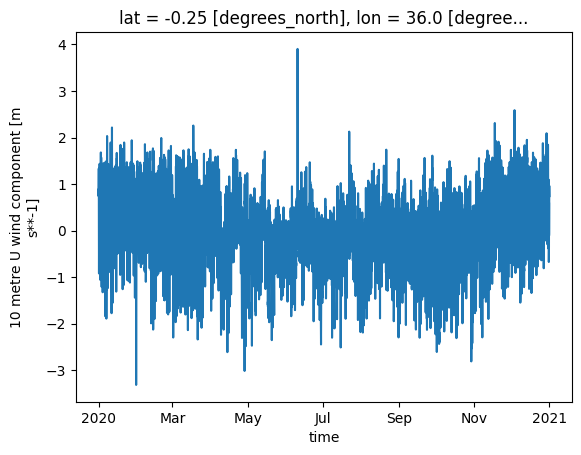

In [8]:
wind1d_u = wind_u['10m_u_component_of_wind'].isel(lat=2, lon=0)
wind1d_v = wind_v['10m_v_component_of_wind'].isel(lat=2, lon=0)
wind1d_u.plot();

## Create a spatiotemporal dataset
We convert each grid point into a location and form a dataframe. We then leverage [(tsl)](https://torch-spatiotemporal.readthedocs.io/en/latest/) to split the wind velocity timeseries into sliding windows with respective forecast horizons. See [this explanation](https://torch-spatiotemporal.readthedocs.io/en/latest/usage/spatiotemporal_dataset.html).

In [9]:
ds_stacked = wind_u.stack(location=("lat", "lon"))

df = (
    ds_stacked
    .drop_vars(["lat", "lon", "location"]) # remove duplicates
    .to_dataframe()
    .reset_index()
)
df_pivot = df.pivot(index="time", columns="location", values="10m_u_component_of_wind")

In [10]:
window_size = 12 
forecast_horizon = 12

torch_dataset = SpatioTemporalDataset(target=df_pivot,
                                      horizon=forecast_horizon,
                                      window=window_size,
                                      stride=1)
print(torch_dataset)

SpatioTemporalDataset(n_samples=8761, n_nodes=54, n_channels=1)


### Normalization and train-val-test split

In [11]:


# Normalize data using mean and std computed over time and node dimensions
scalers = {'target': StandardScaler(axis=(0, 1))}

# Split data sequentially:
#   |------------ dataset -----------|
#   |--- train ---|- val -|-- test --|
splitter = TemporalSplitter(val_len=0.1, test_len=0.2)

dm = SpatioTemporalDataModule(
    dataset=torch_dataset,
    scalers=scalers,
    splitter=splitter,
    batch_size=64,
)
dm.setup()

In [12]:
print(dm)

{Train dataloader: size=6297}
{Validation dataloader: size=688}
{Test dataloader: size=1752}
{Predict dataloader: None}


### RNN for wind speed forecasting

In [25]:
model = RNNModel(input_size=1, output_size=1, horizon=torch_dataset.horizon)

In [26]:
model

RNNModel(
  (input_encoder): Sequential(
    (0): Linear(in_features=1, out_features=32, bias=True)
    (1): ReLU()
  )
  (rnn): RNN(
    (rnn): GRU(32, 32)
  )
  (readout): MLPDecoder(
    (readout): MLP(
      (mlp): Sequential(
        (0): Dense(
          (affinity): Linear(in_features=32, out_features=64, bias=True)
          (activation): ReLU()
          (dropout): Identity()
        )
      )
      (readout): Linear(in_features=64, out_features=12, bias=True)
    )
    (rearrange): Rearrange('b n (h f) -> b h n f', f=1, h=12)
  )
)

In [27]:
loss_fn = MaskedMAE()

metrics = {'mae': MaskedMAE(),
           'mape': MaskedMAPE(),
           'mae_at_3': MaskedMAE(at=2),  # '2' indicates the third time step,
                                          # which correspond to 3 hours ahead
           'mae_at_6': MaskedMAE(at=5),
           'mae_at_12': MaskedMAE(at=11)}

# setup predictor
predictor = Predictor(
    model=model,                   # our initialized model
    optim_class=torch.optim.Adam,  # specify optimizer to be used...
    optim_kwargs={'lr': 0.001},    # ...and parameters for its initialization
    loss_fn=loss_fn,               # which loss function to be used
    metrics=metrics                # metrics to be logged during train/val/test
)

In [28]:
# a class to allow us plot metrics
class MetricTracker(Callback):
    def __init__(self):
        super().__init__()
        self.history = []

    def on_validation_epoch_end(self, trainer, pl_module):
        # Make a copy of the metrics dictionary and append it to the history list
        # The metrics are stored in trainer.logged_metrics or trainer.callback_metrics
        # Use .copy() to ensure the metrics from the *current* epoch are saved.
        metrics = trainer.callback_metrics.copy() 
        self.history.append(metrics)

In [29]:
logger = TensorBoardLogger(save_dir="logs", name="wind_example", version=0)


In [30]:
checkpoint_callback = ModelCheckpoint(
    dirpath='logs',
    save_top_k=1,
    monitor='val_mae',
    mode='min',
)
metric_tracker_callback = MetricTracker()

In [31]:
trainer = pl.Trainer(max_epochs=500,
                     logger=None,
                     accelerator='gpu' if torch.cuda.is_available() else 'cpu',
                     devices=1 if torch.cuda.is_available() else None,
                     limit_train_batches=100,  # end an epoch after 100 updates
                     callbacks=[checkpoint_callback, metric_tracker_callback])

trainer.fit(predictor, datamodule=dm)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name          ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss_fn       │ MaskedMAE        │      0 │ train │     0 │
│ 1 │ train_metrics │ MetricCollection │      0 │ train │     0 │
│ 2 │ val_metrics   │ MetricCollection │      0 │ train │     0 │
│ 3 │ test_metrics  │ MetricCollection │      0 │ train │     0 │
│ 4 │ model         │ RNNModel         │  9.3 K │ train │     0 │
└───┴───────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 9.3 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 9.3 K                                                                                                
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 34                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

Only args ['x'] are forwarded to the model (RNNModel).

`Trainer.fit` stopped: `max_epochs=500` reached.


In [32]:
all_epoch_metrics = metric_tracker_callback.history

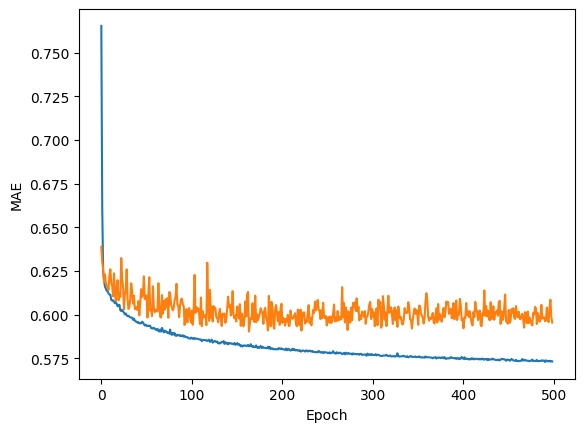

In [33]:
plt.plot([x['train_mae'].item() for x in all_epoch_metrics[2:]])
plt.plot([x['val_mae'].item() for x in all_epoch_metrics[2:]])
plt.xlabel('Epoch')
plt.ylabel('MAE');